# Entregable I — Análisis exploratorio de datos

**Modelo predictivo de riesgo de mora en contratos de leasing de motocicletas**
Modelos y Simulación de Sistemas II — Universidad de Antioquia — Grupo 14

Este notebook caracteriza la base de datos real, define la variable objetivo con su
corte temporal y construye las variables candidatas de las primeras *k* semanas de
cada contrato. Sus resultados alimentan las secciones 1.5 a 1.8 del documento.

**Datos.** Trabaja sobre la copia anonimizada en `data/anon/`, generada con
`src/extraer.py` (ver `README.md`). Los datos son confidenciales de la empresa y no
están en el repositorio. Las reglas de negocio aplicadas están en
`docs/reglas_de_negocio.md`; la lógica del calendario y de la etiqueta está en
`src/ciclos.py` y `src/variables.py`, con pruebas en `tests/`.

**Alcance.** Sede Cartagena. Los montos están en miles de pesos.

**En Google Colab.** Abra este notebook desde la carpeta compartida
`ProyectoModelos2_Colab` (si aparece en "Compartidos conmigo", agréguele antes un acceso
directo en "Mi unidad") y ejecute todo. La primera celda de código conecta Drive y
entra a la carpeta sola; los resultados se guardan en la sesión (`/content/salidas`),
no en la carpeta compartida.

In [1]:
import json
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Funciona con la estructura del repositorio (src/, data/anon/) o con todos los
# archivos sueltos en una misma carpeta, como quedan en la carpeta compartida de Drive.
EN_COLAB = "google.colab" in sys.modules
NOMBRE_CARPETA = "ProyectoModelos2_Colab"


# Ubica la carpeta compartida en Drive: en Mi unidad, dentro de otra carpeta o
# detras de un acceso directo (Colab los expone en .shortcut-targets-by-id).
def buscar_carpeta_drive():
    raices = [Path("/content/drive/MyDrive"), *Path("/content/drive").glob(".shortcut-targets-by-id/*")]
    for patron in (NOMBRE_CARPETA, f"*/{NOMBRE_CARPETA}", f"*/*/{NOMBRE_CARPETA}"):
        for raiz in raices:
            for carpeta in raiz.glob(patron):
                if (carpeta / "ciclos.py").exists():
                    return carpeta
    return None


if EN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    carpeta = buscar_carpeta_drive()
    if carpeta is None:
        raise FileNotFoundError(
            f"No se encontro la carpeta {NOMBRE_CARPETA} en su Drive. Si se la compartieron, "
            "vaya a Google Drive > Compartidos conmigo, clic derecho sobre la carpeta > "
            "Organizar > Agregar acceso directo > Mi unidad, y vuelva a ejecutar todo "
            "(Entorno de ejecucion > Reiniciar y ejecutar todo).")
    os.chdir(carpeta)
    print("Carpeta de trabajo:", carpeta)
RAIZ = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
# En Colab los resultados van a la sesion y no a la carpeta compartida: quien la
# tiene en solo lectura puede ejecutar igual y nadie sobrescribe archivos de otros.
DIR_SALIDA = Path("/content/salidas") if EN_COLAB else RAIZ


def ubicar(archivos, carpetas):
    for carpeta in carpetas:
        if all((carpeta / a).exists() for a in archivos):
            return carpeta
    raise FileNotFoundError(f"No se encontraron {archivos} en {[str(c) for c in carpetas]}. "
                            "Suba esos archivos (ver README) a la misma carpeta del notebook.")


DIR_SRC = ubicar(["ciclos.py", "variables.py"], [RAIZ / "src", Path.cwd()])
DIR_DATOS = ubicar(["abonos.csv.gz", "motos_diario.csv.gz", "rentabilidad.csv.gz"], [RAIZ / "data" / "anon", Path.cwd()])
sys.path.insert(0, str(DIR_SRC))
from ciclos import construir_episodios, pagos_por_dia, construir_ciclos, retiros, CARTAS_RETIRO
from variables import asignar_retiro, marcar_poblacion, etiqueta, variables_entrada

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
DIR_FIG = DIR_SALIDA / "reports" / "figuras"
DIR_FIG.mkdir(parents=True, exist_ok=True)

# Paleta validada (guia de visualizacion): azul y naranja son las dos primeras
# posiciones categoricas; el texto usa tinta neutra, nunca el color de la serie.
AZUL, NARANJA, TINTA, TINTA_2, REJILLA = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#e6e5e0"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "font.size": 10,
    "axes.edgecolor": TINTA_2, "axes.labelcolor": TINTA, "xtick.color": TINTA_2, "ytick.color": TINTA_2,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": REJILLA,
    "axes.axisbelow": True, "axes.titlesize": 11, "axes.titleweight": "bold",
})
CIFRAS = {}  # cifras clave que se exportan para redactar el documento

## 1. Parámetros del estudio

Todos los resultados dependen de estos cuatro valores. Se justifican con evidencia en
la sección 7; cambiarlos aquí recalcula todo el notebook.

| Parámetro | Valor | Significado |
|---|---|---|
| `K` | 8 semanas | ventana de observación: información disponible para predecir |
| `H` | 12 semanas | horizonte de predicción, inmediatamente después de la ventana |
| `X` | 14 días | atraso de un ciclo que define "riesgo grave de mora" (dos cuotas semanales) |
| `INICIO_COHORTE` | 2024-03-30 | primer día de la foto diaria; antes solo se ven los episodios que sobrevivieron |

In [2]:
K, H, X = 8, 12, 14
INICIO_COHORTE = pd.Timestamp("2024-03-30")

## 2. Carga de datos

In [3]:
abonos = pd.read_csv(DIR_DATOS / "abonos.csv.gz", parse_dates=["fecha"])
diario = pd.read_csv(DIR_DATOS / "motos_diario.csv.gz", parse_dates=["fecha_registro"], dtype={"justificacion": str})
rentab = pd.read_csv(DIR_DATOS / "rentabilidad.csv.gz", parse_dates=["fecha_inicio", "fecha_final", "fecha_registro"])
CORTE = abonos.fecha.max()
print(f"Corte de datos: {CORTE.date()}")
for nombre, df in (("abonos", abonos), ("motos_diario", diario), ("rentabilidad", rentab)):
    print(f"{nombre:13s} {len(df):>9,d} filas  {df.shape[1]:>2d} columnas  {df.id_contrato.nunique():>5,d} contratos")

Corte de datos: 2026-10-03
abonos          214,745 filas  10 columnas  3,906 contratos
motos_diario  1,260,006 filas  10 columnas  3,081 contratos
rentabilidad      3,531 filas  10 columnas  2,374 contratos


## 3. Diccionario de datos

La copia ya excluye, desde la extracción, los registros fuera de alcance (empresa
RASTREOYA, identificadores con correo o no numéricos y las ventas a Medellín) y todas
las columnas con datos personales. El contrato se reemplazó por un código (`id_contrato`).

In [4]:
SIGNIFICADO = {
    "abonos": {
        "id_contrato": "Código anónimo del contrato (identifica la moto; se reasigna entre clientes)",
        "fecha": "Fecha del registro de pago",
        "abono": "Pago al canon (reduce el saldo de la moto)",
        "transf": "Pago al canon por transferencia (reduce el saldo; poco común)",
        "multa": "Multa por atraso cobrada en el pago (no reduce el saldo)",
        "repuesto": "Devolución de dinero prestado (repuestos, trámites, SOAT); no reduce el saldo",
        "carta": "SI = abono ficticio que cierra el saldo (la moto deja de estar con el cliente)",
        "cartamotivo": "Motivo de la carta (regreso diario, administración, realquiler, pérdida, pronto pago...)",
        "concepto": "Canal o tipo de registro (EFECTIVO, DIGITACION, EGRESOS...)",
        "empresa": "Empresa del grupo (MOTOHOY, RENTAYA)",
    },
    "motos_diario": {
        "id_contrato": "Código anónimo del contrato",
        "fecha_registro": "Día de la foto diaria",
        "fecha_inicio": "Inicio del episodio (cliente con la moto); 0000-00-00 = trámites pendientes",
        "tipopago": "Frecuencia de pago: SEMANAL, QUINCENAL, MENSAUAL o DIARIO (período de prueba)",
        "dia_canon": "Día de la semana en que vence la cuota (QUI = quincenal)",
        "cuota": "Valor de la cuota por ciclo",
        "no_canon": "Número de cuotas pactadas",
        "diassinpagar": "Días desde el último pago según el sistema (999 = sin pagos aún)",
        "justificacion": "Justificación o marca de gestión vigente ese día",
        "empresa": "Empresa del grupo",
    },
    "rentabilidad": {
        "id_contrato": "Código anónimo del contrato",
        "concepto": "Desenlace del episodio cerrado (NORMAL, PRONTO PAGO o tipo de carta)",
        "fecha_inicio": "Inicio del episodio",
        "fecha_final": "Fin del episodio",
        "fecha_registro": "Fecha en que se registró el cierre",
        "tipopago": "Frecuencia de pago",
        "dia_canon": "Día de vencimiento de la cuota",
        "cuota": "Valor de la cuota",
        "no_canon": "Número de cuotas pactadas",
        "fuente": "Tabla de origen (rentabilidad_activos o rentabilidad_activos_cartas)",
    },
}


def diccionario(nombre, df):
    filas = []
    for col in df.columns:
        s = df[col]
        vacio = s.isna() | s.astype(str).str.strip().isin(["", "nan"])
        if pd.api.types.is_numeric_dtype(s):
            rango = f"{s.min():,.2f} a {s.max():,.2f}"
        elif pd.api.types.is_datetime64_any_dtype(s):
            rango = f"{s.min().date()} a {s.max().date()}"
        elif col == "id_contrato":
            rango = f"{s.nunique():,d} códigos"
        else:
            vc = s[~vacio].value_counts()
            rango = ", ".join(map(str, vc.index[:6])) + (f" (+{len(vc) - 6})" if len(vc) > 6 else "")
        filas.append({"tabla": nombre, "columna": col, "tipo": str(s.dtype), "significado": SIGNIFICADO[nombre][col],
                      "% faltantes": round(vacio.mean() * 100, 1), "rango o categorías": rango})
    return pd.DataFrame(filas)


dicc = pd.concat([diccionario(n, d) for n, d in (("abonos", abonos), ("motos_diario", diario), ("rentabilidad", rentab))])
dicc.to_csv(DIR_SALIDA / "reports" / "diccionario_datos.csv", index=False, encoding="utf-8-sig")
dicc

,tabla,columna,tipo,significado,% faltantes,rango o categorías
0,abonos,id_contrato,str,Código anónimo del contrato (identifica la mot...,0.0,"3,906 códigos"
1,abonos,fecha,datetime64[us],Fecha del registro de pago,0.0,2020-02-09 a 2026-10-03
2,abonos,abono,float64,Pago al canon (reduce el saldo de la moto),0.0,"-300.00 a 18,304.00"
3,abonos,transf,float64,Pago al canon por transferencia (reduce el sal...,0.0,"0.00 a 15,268.50"
4,abonos,multa,float64,Multa por atraso cobrada en el pago (no reduce...,0.0,0.00 a 499.80
5,abonos,repuesto,float64,"Devolución de dinero prestado (repuestos, trám...",0.0,"0.00 a 1,321.00"
6,abonos,carta,str,SI = abono ficticio que cierra el saldo (la mo...,0.0,"NO, SI"
7,abonos,cartamotivo,str,"Motivo de la carta (regreso diario, administra...",81.4,"NADA, CARTA REGRESO DIARIO, CARTA ADMINISTRACI..."
8,abonos,concepto,str,"Canal o tipo de registro (EFECTIVO, DIGITACION...",0.0,"EFECTIVO, DIGITACION, RENTAYA"
9,abonos,empresa,str,"Empresa del grupo (MOTOHOY, RENTAYA)",0.0,"MOTOHOY, RENTAYA"


**Lectura.** Los faltantes altos de `cartamotivo` y `justificacion` son esperables:
solo se llenan cuando hay carta o justificación. Las columnas que importan para el
modelo (fechas, montos, frecuencia, cuota) están completas; el diagnóstico de
faltantes reales se hace en la sección 9, sobre las variables ya construidas.

## 4. Cifras base

In [5]:
motivo = abonos.cartamotivo.fillna("").str.strip().str.upper()
es_carta = abonos.carta.eq("SI")
pagos = pagos_por_dia(abonos)
cartas = (abonos[es_carta].assign(motivo=motivo[es_carta].replace("", "(sin motivo)"))
          .groupby("motivo").agg(filas=("id_contrato", "size"), contratos=("id_contrato", "nunique"))
          .sort_values("filas", ascending=False))
cartas["¿pago real?"] = np.where(cartas.index == "PRONTO PAGO", "sí", "no")
cartas["¿retiro?"] = np.where(cartas.index.isin(CARTAS_RETIRO), "sí", "no")

base = {
    "registros de pago (filas de abonos)": len(abonos),
    "días con pago real (contrato-día)": len(pagos),
    "contratos (motos) distintos": abonos.id_contrato.nunique(),
    "rango de fechas de pago": f"{abonos.fecha.min().date()} a {CORTE.date()}",
    "filas con carta": int(es_carta.sum()),
    "contratos con carta de retiro": int(abonos[es_carta & motivo.isin(CARTAS_RETIRO)].id_contrato.nunique()),
}
CIFRAS["base"] = base
display(pd.Series(base, name="valor").to_frame())
display(cartas)

,valor
registros de pago (filas de abonos),214745
días con pago real (contrato-día),211593
contratos (motos) distintos,3906
rango de fechas de pago,2020-02-09 a 2026-10-03
filas con carta,2546
contratos con carta de retiro,1231


,filas,contratos,¿pago real?,¿retiro?
motivo,,,,
CARTA REGRESO DIARIO,1313,742,no,sí
CARTA ADMINISTRACION,618,598,no,sí
PRONTO PAGO,233,233,sí,no
CARTA REALQUILER,184,171,no,sí
(sin motivo),108,96,no,no
CARTA PERDIDA,57,56,no,sí
CARTA CORRECCION,33,31,no,no


**El número de contrato identifica la moto, no al cliente.** Cuando a un cliente se le
retira la moto, esta se asigna a otro con el mismo número. Por eso la unidad de análisis
es el **episodio**: un cliente con una moto, identificado por (`id_contrato`,
`fecha_inicio`) en la foto diaria.

In [6]:
tp_diario = (diario.assign(fi_valida=diario.fecha_inicio.ne("0000-00-00"))
             .groupby(["id_contrato", "fecha_inicio"]).agg(tipopago=("tipopago", "first"), valida=("fi_valida", "first")))
episodios_por_contrato = diario.loc[diario.fecha_inicio.ne("0000-00-00")].groupby("id_contrato").fecha_inicio.nunique()
print("Tramos (contrato, fecha_inicio) en la foto diaria:", len(tp_diario))
print("  por tipo de pago:", tp_diario[tp_diario.valida].tipopago.value_counts().to_dict())
print("  con fecha_inicio 0000-00-00 (trámites pendientes, se descartan):", int((~tp_diario.valida).sum()))
print("Contratos con 2 o más fechas de inicio distintas:", int((episodios_por_contrato >= 2).sum()), "de", len(episodios_por_contrato))

Tramos (contrato, fecha_inicio) en la foto diaria: 8025
  por tipo de pago: {'SEMANAL': 5191, 'DIARIO': 1006, 'QUINCENAL': 127, 'MENSAUAL': 9}
  con fecha_inicio 0000-00-00 (trámites pendientes, se descartan): 1692
Contratos con 2 o más fechas de inicio distintas: 1732 de 3081


Los tramos `DIARIO` son un período de prueba de alrededor de un mes sin contrato de
propiedad: si el cliente responde, pasa a pago semanal o quincenal con una
`fecha_inicio` nueva. Se descartan, al igual que los tramos con `fecha_inicio`
0000-00-00 (cliente asignado con trámites pendientes, sin la moto todavía).

In [7]:
ep = construir_episodios(diario)
ciclos = construir_ciclos(ep, pagos, CORTE)
ep = asignar_retiro(ep, retiros(abonos))
ep = marcar_poblacion(ep, ciclos, K, H, X, CORTE, INICIO_COHORTE)
desde_cohorte = ep[ep.fecha_inicio >= INICIO_COHORTE]

frec = desde_cohorte.tipopago.value_counts()
emp = desde_cohorte.empresa.value_counts()
CIFRAS["episodios"] = {
    "episodios de leasing (todos)": len(ep),
    "episodios desde la cohorte": len(desde_cohorte),
    "semanal": int(frec.get("SEMANAL", 0)), "quincenal": int(frec.get("QUINCENAL", 0)),
    "motohoy": int(emp.get("MOTOHOY", 0)), "rentaya": int(emp.get("RENTAYA", 0)),
    "con retiro (desde la cohorte)": int(desde_cohorte.fecha_retiro.notna().sum()),
    "ciclos de pago esperados (todos)": len(ciclos),
}
pd.Series(CIFRAS["episodios"], name="valor").to_frame()

,valor
episodios de leasing (todos),5316
episodios desde la cohorte,4506
semanal,4371
quincenal,135
motohoy,3102
rentaya,1404
con retiro (desde la cohorte),1825
ciclos de pago esperados (todos),178526


In [8]:
just = diario.justificacion.fillna("").str.strip().str.upper()
grupo = pd.Series("no es justificación", index=just.index)
from variables import ENFERMEDAD, INMOVILIZACION, RETENCION, PROBLEMA
for nombre, valores in (("enfermedad o calamidad", ENFERMEDAD), ("inmovilización", INMOVILIZACION),
                        ("retención temporal (MOTO INGRESADA)", RETENCION), ("cliente problema", PROBLEMA)):
    grupo[just.isin(valores)] = nombre
d_j = diario[just.ne("")].assign(grupo=grupo[just.ne("")], just=just[just.ne("")]).sort_values(["id_contrato", "fecha_registro"])
# Un evento es un tramo de dias consecutivos con la misma justificacion
d_j["nuevo"] = (d_j.groupby(["id_contrato", "just"]).fecha_registro.diff().dt.days.ne(1))
tabla_j = d_j.groupby("grupo").agg(dias_registrados=("just", "size"), eventos=("nuevo", "sum"), contratos=("id_contrato", "nunique"))
CIFRAS["justificaciones"] = tabla_j.eventos.astype(int).to_dict()
tabla_j.sort_values("eventos", ascending=False)

,dias_registrados,eventos,contratos
grupo,,,
no es justificación,12177,3643,1288
retención temporal (MOTO INGRESADA),3193,1174,577
cliente problema,2473,803,392
inmovilización,2323,748,396
enfermedad o calamidad,899,280,175


## 5. Fecha esperada de pago

`np_his_abonos` no tiene una columna de fecha esperada. Se reconstruye con el
calendario de cada episodio: para pago semanal, cada `dia_canon` después de la fecha
de inicio; para quincenal, cada 14 días. La figura muestra en qué día caen los pagos
reales respecto al `dia_canon` del episodio vigente: la mitad cae exactamente ese día,
lo que confirma que es la fecha esperada.

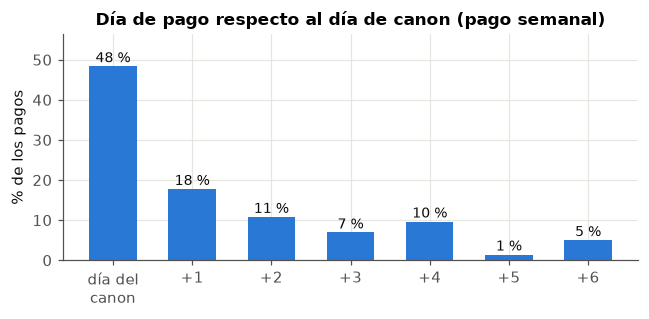

In [9]:
sem = ep[ep.tipopago.eq("SEMANAL") & ep.dia_canon_num.notna()]
m = pd.merge_asof(pagos.sort_values("fecha"), sem[["id_contrato", "fecha_inicio", "fin", "dia_canon_num"]].sort_values("fecha_inicio"),
                  left_on="fecha", right_on="fecha_inicio", by="id_contrato", direction="backward")
m = m[m.dia_canon_num.notna() & (m.fecha <= m.fin) & (m.fecha >= "2024-01-01")]
rel = ((m.fecha.dt.weekday - m.dia_canon_num) % 7).astype(int)
dist = rel.value_counts(normalize=True).sort_index() * 100
etiquetas = ["día del\ncanon", "+1", "+2", "+3", "+4", "+5", "+6"]
fig, ax = plt.subplots(figsize=(6, 3))
ax.bar(etiquetas, dist.values, color=AZUL, width=0.6)
for i, v in enumerate(dist.values):
    ax.text(i, v + 1, f"{v:.0f} %", ha="center", color=TINTA, fontsize=9)
ax.set_ylabel("% de los pagos")
ax.set_title("Día de pago respecto al día de canon (pago semanal)")
ax.set_ylim(0, dist.max() + 8)
fig.tight_layout(); fig.savefig(DIR_FIG / "dia_pago_vs_canon.png"); plt.show()

## 6. Consistencia entre multa y días de atraso

Cada día con pago (cualquier dinero entregado: abono, transferencia, multa o repuesto)
cubre un ciclo del calendario, o varios si el pago al canon alcanza varias cuotas. El
atraso de un ciclo es la diferencia entre la fecha de ese pago y la fecha esperada.

In [10]:
c = ciclos[ciclos.pagado & (ciclos.fecha_pago >= "2024-01-01")].copy()
c["tramo"] = pd.cut(c.dias_atraso, [-1, 0, 2, 6, 13, 10**5], labels=["0", "1-2", "3-6", "7-13", "14+"])
consist = c.groupby("tramo", observed=True).agg(
    ciclos=("multa", "size"),
    sin_multa=("multa", lambda s: (s == 0).mean() * 100),
    multa_15=("multa", lambda s: (s == 15).mean() * 100),
    multa_25=("multa", lambda s: (s == 25).mean() * 100),
    otra=("multa", lambda s: (~s.isin([0, 15, 25])).mean() * 100),
).round(1)
rho = c[["multa", "dias_atraso"]].corr("spearman").iloc[0, 1]
CIFRAS["multa"] = {"spearman_multa_atraso": round(rho, 3), **{f"sin_multa_{t}": consist.loc[t, "sin_multa"] for t in consist.index}}
print(f"Correlación de Spearman multa ~ días de atraso: {rho:.3f}")
consist.rename(columns={"sin_multa": "% sin multa", "multa_15": "% multa 15", "multa_25": "% multa 25", "otra": "% otro valor"})

Correlación de Spearman multa ~ días de atraso: 0.608


,ciclos,% sin multa,% multa 15,% multa 25,% otro valor
tramo,,,,,
0,61018,96.2,1.2,2.3,0.4
1-2,29411,16.9,61.5,18.9,2.7
3-6,19979,8.9,0.9,82.2,8.0
7-13,15901,39.5,15.6,35.7,9.1
14+,19217,38.0,12.6,34.4,15.1


**Lectura.** La multa sigue escalones según el atraso dentro de la semana: sin atraso
casi nunca hay multa, con 1 a 2 días es de 15 mil y desde 3 días es de 25 mil. Desde
7 días la relación se debilita: un cliente que va una semana atrasado pero paga el
día del canon muchas veces no recibe multa. La multa mide el atraso **dentro de la
semana**, no el acumulado; por eso no es del todo redundante con el atraso, aunque sí
lo es con la proporción de ciclos atrasados (sección 8).

## 7. Distribución del atraso y elección de *k*, *H* y *X*

Percentiles del atraso por ciclo (días): {0.5: 1.0, 0.75: 8.0, 0.9: 31.0, 0.95: 58.0, 0.99: 162.0}


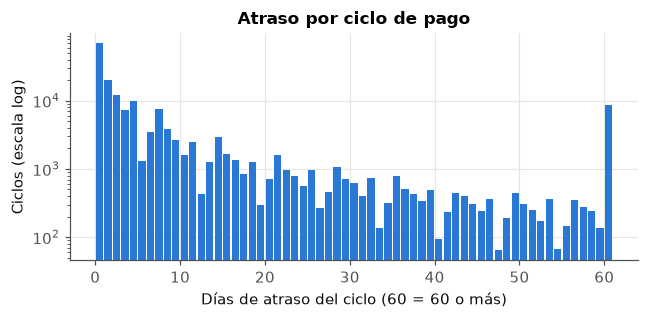

In [11]:
pct = ciclos.dias_atraso.quantile([.5, .75, .9, .95, .99])
CIFRAS["atraso_ciclo_percentiles"] = pct.round(1).to_dict()
print("Percentiles del atraso por ciclo (días):", pct.round(1).to_dict())
fig, ax = plt.subplots(figsize=(6, 3))
v = ciclos.dias_atraso.clip(upper=60)
ax.hist(v, bins=np.arange(0, 62, 1), color=AZUL, rwidth=0.85)
ax.set_yscale("log")
ax.set_xlabel("Días de atraso del ciclo (60 = 60 o más)")
ax.set_ylabel("Ciclos (escala log)")
ax.set_title("Atraso por ciclo de pago")
fig.tight_layout(); fig.savefig(DIR_FIG / "atraso_por_ciclo.png"); plt.show()

**Elección de X.** Para cada episodio se toma el máximo atraso de un ciclo en la
ventana de predicción y se compara con el porcentaje que termina con la moto retirada.
El retiro es discrecional y no es la etiqueta, pero sirve para validar que el umbral
separa comportamientos de riesgo real.

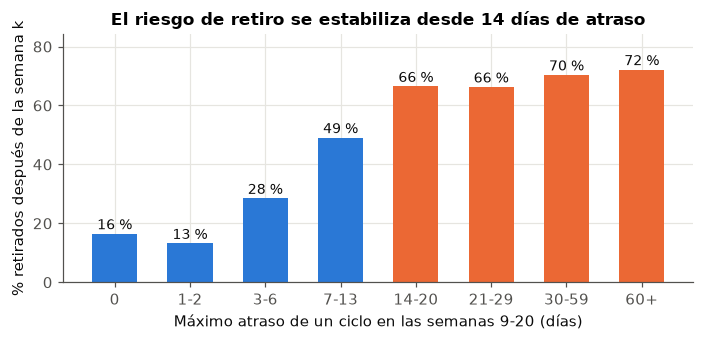

,episodios,pct_retiro
tramo,,
0,423,16.5
1-2,660,13.2
3-6,582,28.5
7-13,458,49.1
14-20,251,66.5
21-29,208,66.3
30-59,199,70.4
60+,108,72.2


In [12]:
def max_atraso_ventana(pob, k, h):
    cc = ciclos[ciclos.id_episodio.isin(pob.id_episodio)].merge(pob[["id_episodio", "fecha_inicio"]])
    semana = (cc.fecha_esperada - cc.fecha_inicio).dt.days / 7
    cc = cc[(semana > k) & (semana <= k + h)]
    return cc.groupby("id_episodio").dias_atraso.max().reindex(pob.id_episodio).fillna(0)

pob = ep[ep.motivo_exclusion.isna()]
mx = max_atraso_ventana(pob, K, H).values
retiro_post = (pob.fecha_retiro > pob.fecha_inicio + pd.Timedelta(weeks=K)).values
tramos = pd.cut(mx, [-1, 0, 2, 6, 13, 20, 29, 59, 10**5], labels=["0", "1-2", "3-6", "7-13", "14-20", "21-29", "30-59", "60+"])
t_x = pd.DataFrame({"tramo": tramos, "retiro": retiro_post}).groupby("tramo", observed=True).agg(
    episodios=("retiro", "size"), pct_retiro=("retiro", lambda s: s.mean() * 100)).round(1)
CIFRAS["retiro_por_atraso_max"] = t_x.pct_retiro.to_dict()

fig, ax = plt.subplots(figsize=(6.5, 3.2))
colores = [NARANJA if t in ("14-20", "21-29", "30-59", "60+") else AZUL for t in t_x.index]
ax.bar(t_x.index.astype(str), t_x.pct_retiro, color=colores, width=0.6)
for i, (p, n) in enumerate(zip(t_x.pct_retiro, t_x.episodios)):
    ax.text(i, p + 1.5, f"{p:.0f} %", ha="center", color=TINTA, fontsize=9)
ax.set_xlabel(f"Máximo atraso de un ciclo en las semanas {K+1}-{K+H} (días)")
ax.set_ylabel("% retirados después de la semana k")
ax.set_title(f"El riesgo de retiro se estabiliza desde {X} días de atraso")
ax.set_ylim(0, t_x.pct_retiro.max() + 12)
fig.tight_layout(); fig.savefig(DIR_FIG / "retiro_vs_atraso_maximo.png"); plt.show()
t_x

**Elección de k y H.** La tabla compara combinaciones: tamaño de la población,
episodios retirados antes de poder predecir y prevalencia de la etiqueta. Un *k*
pequeño permite actuar antes y conserva más episodios, pero con pocos ciclos las
variables de variabilidad se estiman mal; un *k* grande pierde los retiros tempranos.

In [13]:
filas = []
for k in (4, 6, 8, 12):
    for h in (8, 12, 26):
        e = marcar_poblacion(ep.drop(columns=["motivo_exclusion", "semanas", "cerrado"]), ciclos, k, h, X, CORTE, INICIO_COHORTE)
        p = e[e.motivo_exclusion.isna()]
        y_kh = etiqueta(p, ciclos, k, h, X)
        filas.append({"k": k, "H": h, "población": len(p),
                      "cerrados antes de k": int((e.motivo_exclusion == "cerrado antes de la semana k").sum()),
                      "sin desenlace aún": int((e.motivo_exclusion == "sin desenlace observable aun").sum()),
                      "% positivos": round(y_kh.mean() * 100, 1)})
rejilla = pd.DataFrame(filas)
rejilla.style.apply(lambda r: ["font-weight: bold" if (r.k == K and r.H == H) else "" for _ in r], axis=1)

,k,H,población,cerrados antes de k,sin desenlace aún,% positivos
0,4,8,3611,375,233,31.200000
1,4,12,3523,375,320,38.100000
2,4,26,3215,375,626,55.900000
3,6,8,3264,692,235,29.100000
4,6,12,3164,692,333,36.300000
5,6,26,2881,692,615,53.500000
6,8,8,3007,994,219,28.300000
7,8,12,2889,994,336,35.500000
8,8,26,2632,994,592,51.900000
9,12,8,2530,1469,236,27.900000


**Decisión.** `K` = 8 semanas (8 ciclos semanales o 4 quincenales, suficientes para
medir regularidad y variabilidad), `H` = 12 semanas (el horizonte de 3 meses es el de
mejor desempeño en [3] y conserva episodios de 2026) y `X` = 14 días (dos cuotas
semanales sin pagar, donde el riesgo de retiro deja de crecer).

## 8. Población, etiqueta y corte temporal

```
fecha_inicio            t_k = inicio + K semanas              t_k + H semanas
     |------- ventana de observación -------|------- ventana de predicción -------|
       variables de entrada (solo fechas <= t_k)     etiqueta (ciclos que vencen aquí)
```

- **Variables de entrada:** solo información con fecha menor o igual a t_k. Un ciclo
  vencido antes de t_k y pagado después se ve como "sin pagar" con el atraso
  acumulado hasta t_k, que es lo que se sabría ese día (prueba en
  `tests/test_ciclos.py::test_variables_de_entrada_no_ven_informacion_posterior_a_k`).
- **Etiqueta (y = 1):** algún ciclo que vence en (t_k, t_k + H] alcanza X o más días de
  atraso, o nunca se pagó porque el episodio se cerró (la moto se retiró antes de
  llegar a X días). En otro caso y = 0.
- **Población:** episodios que siguen con la moto en t_k y cuyo desenlace ya es
  observable. El retiro y las marcas de gestión nunca forman parte de la etiqueta.

In [14]:
embudo = ep.motivo_exclusion.fillna("EN LA POBLACIÓN").value_counts()
CIFRAS["embudo"] = embudo.to_dict()
display(embudo.to_frame("episodios"))

y = etiqueta(pob, ciclos, K, H, X)
cc = ciclos[ciclos.id_episodio.isin(pob.id_episodio)].merge(pob[["id_episodio", "fecha_inicio", "cerrado"]])
semana = (cc.fecha_esperada - cc.fecha_inicio).dt.days / 7
cc = cc[(semana > K) & (semana <= K + H)]
por_atraso = cc[cc.dias_atraso >= X].id_episodio.unique()
solo_nunca = set(y[y == 1].index) - set(por_atraso)
con_carta = pob.set_index("id_episodio").loc[list(solo_nunca)].fecha_retiro.notna().sum()
CIFRAS["etiqueta"] = {"poblacion": len(pob), "positivos": int(y.sum()), "pct_positivos": round(y.mean() * 100, 1),
                      "positivos_por_atraso": len(por_atraso), "positivos_solo_nunca_pagado": len(solo_nunca),
                      "de_esos_con_carta": int(con_carta), "razon_negativos_positivos": round((1 - y.mean()) / y.mean(), 2)}
pd.Series(CIFRAS["etiqueta"], name="valor").to_frame()

,episodios
motivo_exclusion,
EN LA POBLACIÓN,2889
cerrado antes de la semana k,994
inicio antes de la cohorte,810
sin desenlace observable aun,336
error de asignacion (<= 1 semana sin pagos),225
cierre con atraso censurado sin carta de retiro,44
sin dia_canon,18


,valor
poblacion,2889.00
positivos,1026.00
pct_positivos,35.50
positivos_por_atraso,766.00
positivos_solo_nunca_pagado,260.00
de_esos_con_carta,260.00
razon_negativos_positivos,1.82


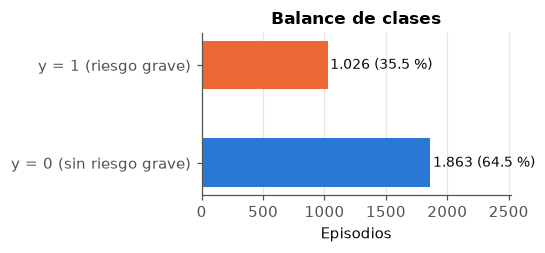

Prevalencia por año de inicio: {2024: 30.3, 2025: 37.9, 2026: 40.2}
Prevalencia por empresa: {'MOTOHOY': 30.3, 'RENTAYA': 54.6}


In [15]:
fig, ax = plt.subplots(figsize=(5, 2.4))
conteo = y.value_counts().sort_index()
ax.barh(["y = 0 (sin riesgo grave)", "y = 1 (riesgo grave)"], conteo.values, color=[AZUL, NARANJA], height=0.5)
for i, v in enumerate(conteo.values):
    ax.text(v + 20, i, f"{v:,d} ({v / conteo.sum() * 100:.1f} %)".replace(",", "."), va="center", color=TINTA, fontsize=9)
ax.set_xlim(0, conteo.max() * 1.35)
ax.set_xlabel("Episodios")
ax.set_title("Balance de clases")
ax.grid(axis="y", visible=False)
fig.tight_layout(); fig.savefig(DIR_FIG / "balance_clases.png"); plt.show()

anio = pob.fecha_inicio.dt.year
print("Prevalencia por año de inicio:", (y.groupby(anio.values).mean() * 100).round(1).to_dict())
print("Prevalencia por empresa:", (y.groupby(pob.empresa.values).mean() * 100).round(1).to_dict())

## 9. Variables candidatas de las primeras *k* semanas

Las variables se expresan como proporciones o promedios por ciclo, no como conteos
absolutos, para que sean comparables entre frecuencias. "Semanas observadas" es igual
a *k* para todos los episodios de la población, así que no se incluye como variable;
su equivalente por frecuencia es `ciclos_esperados`.

In [16]:
Xv = variables_entrada(pob, ciclos, pagos, diario, K)
DESCRIPCION = {
    "ciclos_esperados": "Cuotas que vencieron en la ventana",
    "prop_ciclos_atrasados": "Proporción de ciclos con atraso >= 1 día",
    "prop_ciclos_atraso_3mas": "Proporción de ciclos con atraso >= 3 días",
    "atraso_promedio": "Días de atraso promedio por ciclo",
    "atraso_maximo": "Máximo atraso de un ciclo",
    "ciclos_sin_pagar_k": "Ciclos vencidos sin pagar en t_k",
    "dias_con_pago": "Días con algún pago",
    "dias_hasta_primer_pago": "Días entre el inicio y el primer pago",
    "pago_canon_total": "Abono + transferencia acumulados",
    "cv_pago_canon": "Coeficiente de variación del pago al canon",
    "multa_acumulada": "Multa acumulada",
    "prop_pagos_con_multa": "Proporción de pagos con multa",
    "repuesto_acumulado": "Dinero devuelto por préstamos",
    "pagos_por_ciclo": "Días con pago por ciclo esperado",
    "deficit_relativo": "1 - pago al canon / (cuota x ciclos)",
    "justif_enfermedad": "Eventos de justificación por enfermedad o calamidad",
    "justif_inmovilizacion": "Eventos de justificación por inmovilización",
    "retencion_temporal": "Eventos de moto ingresada (marca de gestión)",
    "cliente_problema": "Eventos de cliente problema (marca de gestión)",
    "tipopago": "Frecuencia de pago", "empresa": "Empresa", "cuota": "Valor de la cuota",
    "no_canon": "Cuotas pactadas", "dia_canon": "Día de vencimiento",
}
num = Xv.select_dtypes("number")
resumen = pd.DataFrame({
    "descripción": pd.Series(DESCRIPCION),
    "% faltantes": (Xv.isna().mean() * 100).round(1),
    "mediana": num.median().round(2),
    "media y=0": num[y.values == 0].mean().round(2),
    "media y=1": num[y.values == 1].mean().round(2),
    "Spearman con y": num.corrwith(y.astype(float), method="spearman").round(3),
}).loc[list(DESCRIPCION)]
resumen.to_csv(DIR_SALIDA / "reports" / "variables_candidatas.csv", encoding="utf-8-sig")
resumen

,descripción,% faltantes,mediana,media y=0,media y=1,Spearman con y
ciclos_esperados,Cuotas que vencieron en la ventana,0.0,8.00,7.94,7.97,0.038
prop_ciclos_atrasados,Proporción de ciclos con atraso >= 1 día,0.0,0.25,0.23,0.51,0.412
prop_ciclos_atraso_3mas,Proporción de ciclos con atraso >= 3 días,0.0,0.00,0.07,0.28,0.442
atraso_promedio,Días de atraso promedio por ciclo,0.0,0.38,0.80,3.92,0.457
atraso_maximo,Máximo atraso de un ciclo,0.0,1.00,2.12,9.22,0.462
ciclos_sin_pagar_k,Ciclos vencidos sin pagar en t_k,0.0,0.00,0.29,1.49,0.451
dias_con_pago,Días con algún pago,0.0,8.00,7.69,6.50,-0.418
dias_hasta_primer_pago,Días entre el inicio y el primer pago,2.9,5.00,5.04,5.36,0.028
pago_canon_total,Abono + transferencia acumulados,0.0,1575.00,1573.88,1308.46,-0.372
cv_pago_canon,Coeficiente de variación del pago al canon,3.3,0.13,0.14,0.18,0.145


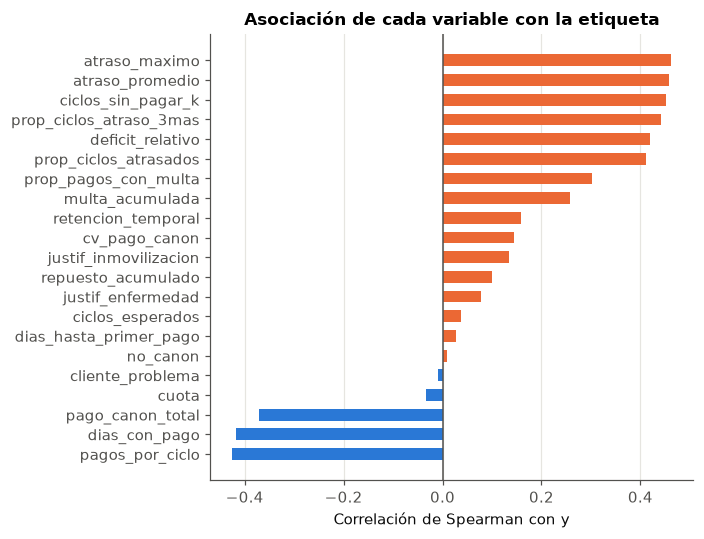

In [17]:
fig, ax = plt.subplots(figsize=(6.5, 5))
r = resumen["Spearman con y"].dropna().sort_values()
ax.barh(r.index, r.values, color=[NARANJA if v > 0 else AZUL for v in r.values], height=0.6)
ax.axvline(0, color=TINTA_2, lw=1)
ax.set_xlabel("Correlación de Spearman con y")
ax.set_title("Asociación de cada variable con la etiqueta")
ax.grid(axis="y", visible=False)
fig.tight_layout(); fig.savefig(DIR_FIG / "spearman_variables.png"); plt.show()

**Redundancia entre multa y atraso.**

In [18]:
pares = [("prop_pagos_con_multa", "prop_ciclos_atrasados"), ("multa_acumulada", "atraso_promedio"),
         ("pagos_por_ciclo", "dias_con_pago"), ("atraso_maximo", "atraso_promedio"), ("deficit_relativo", "ciclos_sin_pagar_k")]
red = pd.DataFrame([{"variable A": a, "variable B": b, "Spearman": round(num[[a, b]].corr("spearman").iloc[0, 1], 3)} for a, b in pares])
CIFRAS["redundancia"] = {f"{a}~{b}": s for a, b, s in red.itertuples(index=False)}
red

,variable A,variable B,Spearman
0,prop_pagos_con_multa,prop_ciclos_atrasados,0.841
1,multa_acumulada,atraso_promedio,0.656
2,pagos_por_ciclo,dias_con_pago,0.984
3,atraso_maximo,atraso_promedio,0.973
4,deficit_relativo,ciclos_sin_pagar_k,0.788


## 10. Datos faltantes y estrategia de imputación

Faltantes reales observados en las fuentes y en las variables construidas:

In [19]:
falt = Xv.isna().sum()
falt = falt[falt > 0]
sin_pago = Xv.dias_con_pago.eq(0)
diag = pd.DataFrame({
    "faltantes": falt,
    "% de la población": (falt / len(Xv) * 100).round(1),
    "coinciden con 'sin pagos en la ventana'": [int((Xv[c].isna() & sin_pago).sum()) for c in falt.index],
    "coinciden con 'un solo pago'": [int((Xv[c].isna() & Xv.dias_con_pago.eq(1)).sum()) for c in falt.index],
})
print("Episodios sin ningún pago en la ventana:", int(sin_pago.sum()), "| tasa de y=1 en ellos:", round(y[sin_pago.values].mean() * 100, 1), "%")
print("Episodios semanales sin dia_canon (excluidos):", CIFRAS["embudo"].get("sin dia_canon", 0))
print("Pagos con diassinpagar = 999 en la foto diaria:", int((diario.diassinpagar == 999).sum()))
CIFRAS["faltantes"] = falt.to_dict()
diag

Episodios sin ningún pago en la ventana: 84 | tasa de y=1 en ellos: 76.2 %
Episodios semanales sin dia_canon (excluidos): 18
Pagos con diassinpagar = 999 en la foto diaria: 39760


,faltantes,% de la población,coinciden con 'sin pagos en la ventana',coinciden con 'un solo pago'
dias_hasta_primer_pago,84,2.9,84,0
cv_pago_canon,94,3.3,84,10
prop_pagos_con_multa,84,2.9,84,0


**Estrategia.** Ningún faltante se rellena con un valor inventado sin dejar rastro:

| Caso | Causa | Tratamiento |
|---|---|---|
| `dias_hasta_primer_pago`, `prop_pagos_con_multa` | episodio sin ningún pago en la ventana | no son faltantes al azar: se imputa el valor que corresponde a "no pagó" (largo de la ventana; 0) **y** se agrega un indicador `sin_pagos_k` |
| `cv_pago_canon` | 0 o 1 pago: la variación no está definida | se imputa 0 con el indicador `sin_pagos_k` o `un_solo_pago`; el valor se fija con datos de entrenamiento |
| `dia_canon` ausente (18 episodios) | sin calendario posible | se excluyen (0,4 %); imputarlo sería inventar la fecha esperada |
| `diassinpagar` = 999 | código del sistema para "sin pagos aún" | se trata como faltante, no como 999 días |
| multa = 0 entre 2020 y 2022 | la multa no se registraba | fuera de la cohorte (inicia en 2024-03-30) |
| atraso de ciclos nunca pagados | episodio cerrado o activo al corte | no se imputa: es un atraso censurado (al menos esos días) |

Cualquier imputación que dependa de estadísticos (mediana, por ejemplo) se ajusta
solo con el conjunto de entrenamiento, dentro del pipeline de validación cruzada.

## 11. Codificación y balance de clases

- **Codificación:** `tipopago` (2 niveles) y `empresa` (2 niveles) se codifican como
  binarias; `dia_canon` (MAR, MIE, JUE, QUI) con one-hot. Las demás son numéricas y se
  escalan (estandarización) dentro del pipeline.
- **Balance:** la razón entre clases se muestra abajo. Es un desbalance moderado; se
  compararán ponderación de clases (`class_weight`), submuestreo y SMOTE **solo
  dentro de los pliegues de entrenamiento**, y se evaluará con métricas sensibles al
  desbalance (AUC, G-mean, exactitud balanceada, KS, Brier).

In [20]:
print(f"y=1: {y.sum():,d} | y=0: {(y == 0).sum():,d} | razón 1:{CIFRAS['etiqueta']['razon_negativos_positivos']}")

y=1: 1,026 | y=0: 1,863 | razón 1:1.82


## 12. Exportar cifras para el documento

In [21]:
def a_json(o):
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.floating,)): return float(o)
    return str(o)

CIFRAS["parametros"] = {"K": K, "H": H, "X": X, "inicio_cohorte": str(INICIO_COHORTE.date()), "corte": str(CORTE.date())}
(DIR_SALIDA / "reports" / "cifras_eda.json").write_text(json.dumps(CIFRAS, indent=2, ensure_ascii=False, default=a_json), encoding="utf-8")
Xv.join(y).join(pob.set_index("id_episodio").fecha_inicio).to_csv((DIR_SALIDA if EN_COLAB else DIR_DATOS) / "dataset_modelo.csv.gz")
print(f"Resultados guardados en {DIR_SALIDA / 'reports'}")

Resultados guardados en C:\Users\LeNoVo\Documents\proyecto_modelos_2\reports
